In [1]:
# CHEE 400 Process Simulation & Design 
#Project_1: Engineering Tool
#Lou-Ann Dupuis
#Exothermic CSTR Sizing with Coupled Thermal Jacket Duty & Conversion Profiling

In [2]:
##Section 1

###Problem Statement 
#In chemical reactor engineering, designing and sizing continuous stirred tank reactors for exothermic liquid phase reactions, students are usually just asked to calculate the vessel volume needed to meet the conversion requirement or target. Exothermic reactions release important amounts of heat, so if the cooling jacket cannot remove the heat rapidly, it will overheat the reactor. According to the U.S. Chemical Safety Board Investigation of the fatal Synthron facility explosion (https://www.csb.gov/final-csb-report-on-synthron-explosion-finds-inadequate-safety-controls-for-chemical-reaction-hazards/), plant operators did not documented the cooling equipment capacity properly. A fatal runway explosion happened when a feed change increased the reaction heat release (by 2.3) which overwhelmed the cooling system. In reality, calculating the reactor sizing and cooling loads across conversions is time consuming; it probably requires a few hours to show how quickly the reactor volume and cooling requirements increase close to high conversions. 

    ####Value proposition 
#For chemical engineering students or professionals who design the process equipment that need to size an isothermal CSTR while determining its cooling jacket requirements, my app is a kinetic sizing and thermal jacket duty analyzer. Unlike traditional homework calculators that only take into account vessel volume, my app outputs the required reactor volume and heat removal duty in kW. It also creates a plot demonstrating the profile of vessel size and thermal load across target conversions.
    

In [ ]:
###Section 2: Project Description & Engineering Basis:

This application is for liquid-phase, steady state isothermal CSTR design, with the addition of thermal utility sizing. The reaction respects the first order irreversible kinetics.

    ### Mathematical Equations

1. Inlet Molar Flow Rate (F_ao): Number of moles of reactant A entering the reactor every minute: 
F_ao = v_o * C_ao    (mol/min)
2. Reactor Volume in L: Volume needed for a target conversion X_a:
V (Liters) = (v_o * X_a) / (k * (1-X_a))
3. Space time (tau) in min: Average time fluid stays inside reactor:
tau (min) = V / v_o = (X_a / (k*(1-X_a)))
4. Cooling jacket Duty (Q_duty): Heat rate required to be removed to maintain steady temperature, converted to kW: 
Qduty = (F_ao * X_a * (- Delta H_(rxn))) / 60 (#conversion to kW)

    *v_o = Volumetric feed rate (L/min)
    *C_ao = Inlet reactant concentration (Mol/L)
    *k = First order reaction constant (min^-1)
    *X_a = Fractional conversion ( 0 < X_a < 1 ) 
    *(- Delta H_(rxn)) = Heat released by reaction (kJ/mol)

## Operational Goals
*Calculate reactor volume and cooling load (Q_duty) instantly from user inputs
*Show an interactive dual-Axis graph showing how reactor volume (exponential curve) and cooling duty (linear curve) change with conversion.
*It will alert the user if conversion exceeds single tank limits (0.95) or if the cooling duty is higher than the jacket capacity (Q_duty > Q_limit)

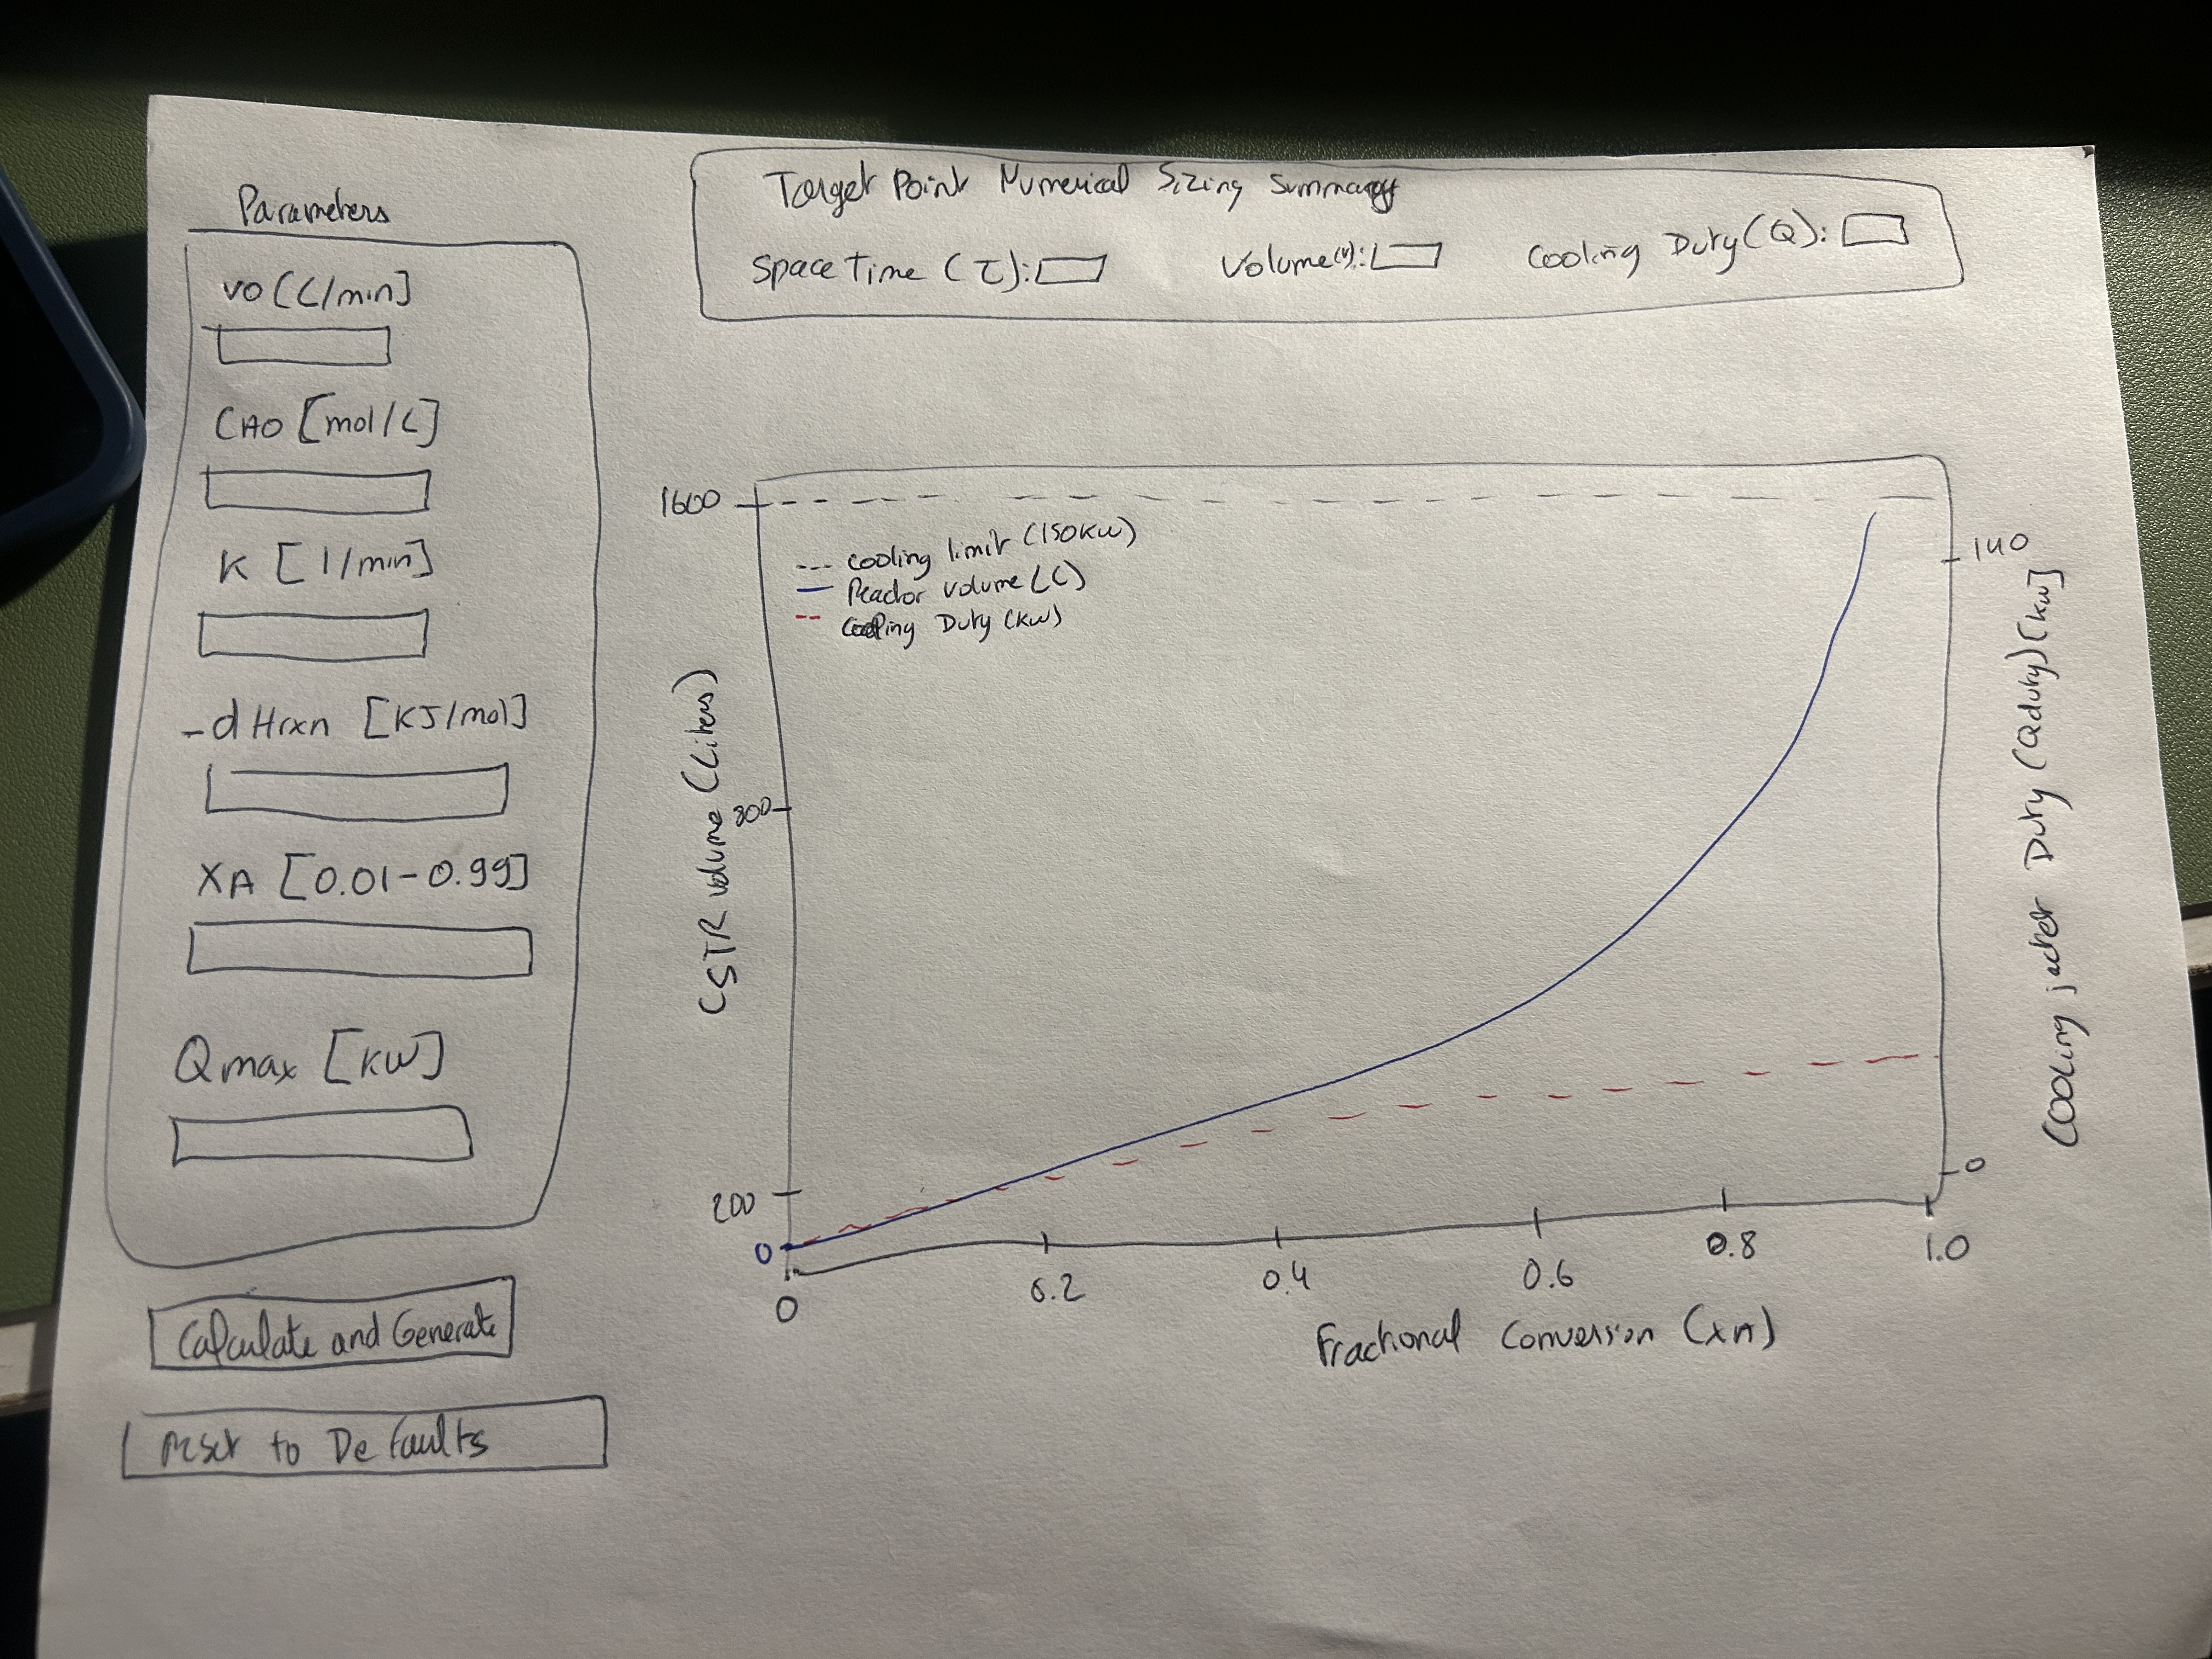

In [4]:
## Section 3: GUI Sketch Image

from IPython.display import Image, display
display(Image(filename="CSTR_GUI_Sketch.jpg", width=750))

In [ ]:
### Section 4: Python Code for App and GUI


import tkinter as tk
from tkinter import messagebox
import numpy as np
import matplotlib
matplotlib.use("TkAgg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg, NavigationToolbar2Tk


class CSTRApp(tk.Tk):
    def __init__(self):
        super().__init__()
        
        self.title("Exothermic CSTR Sizer & Thermal Duty Analyzer - CHEE 400")
        self.geometry("1100x720")
        self.minsize(950, 650)
        
        # Color Palette & Styling
        self.bg_color = "#f4f6f9"
        self.frame_bg = "#ffffff"
        self.accent_color = "#1f4e78"
        self.alert_bg = "#fff2f2"
        self.configure(bg=self.bg_color)
        
        self._init_layout()
        self._set_default_values()
        self.calculate_and_plot()

    def _init_layout(self):
        # ----------------------------------------------------
        # Top Header Banner
        # ----------------------------------------------------
        header_frame = tk.Frame(self, bg=self.accent_color, pady=10)
        header_frame.pack(fill=tk.X)
        header_title = tk.Label(
            header_frame, 
            text="Exothermic CSTR Kinetic Sizer & Jacket Duty Profiler", 
            font=("Helvetica", 16, "bold"), 
            fg="white", 
            bg=self.accent_color
        )
        header_title.pack()
        header_sub = tk.Label(
            header_frame, 
            text="CHEE 400 | Chemical Reaction Engineering & Thermal Management", 
            font=("Helvetica", 9), 
            fg="#d9e2ec", 
            bg=self.accent_color
        )
        header_sub.pack()

        # Main Paned Container
        main_container = tk.Frame(self, bg=self.bg_color, padx=10, pady=10)
        main_container.pack(fill=tk.BOTH, expand=True)

        # ----------------------------------------------------
        # Left Panel: User Inputs & Controls
        # ----------------------------------------------------
        left_panel = tk.LabelFrame(
            main_container, 
            text=" Reactor & Kinetic Parameters ", 
            font=("Helvetica", 11, "bold"),
            bg=self.frame_bg, 
            padx=15, 
            pady=15
        )
        left_panel.pack(side=tk.LEFT, fill=tk.Y, padx=5, pady=5)

        # Input field definitions
        self.entries = {}
        input_fields = [
            ("Volumetric Flow (v₀) [L/min]:", "v0"),
            ("Inlet Concentration (Cₐ₀) [mol/L]:", "ca0"),
            ("Rate Constant (k) [1/min]:", "k"),
            ("Heat of Reaction (-ΔHᵣₓₙ) [kJ/mol]:", "dh"),
            ("Target Conversion (Xₐ) [0.01 - 0.99]:", "xa"),
            ("Cooling Safety Limit (Qₘₐₓ) [kW]:", "q_limit")
        ]

        for i, (label_text, key) in enumerate(input_fields):
            lbl = tk.Label(left_panel, text=label_text, font=("Helvetica", 10), bg=self.frame_bg, anchor="w")
            lbl.grid(row=i*2, column=0, sticky="w", pady=(6, 1))
            
            entry = tk.Entry(left_panel, font=("Helvetica", 10), width=24, relief=tk.SOLID, borderwidth=1)
            entry.grid(row=i*2 + 1, column=0, sticky="ew", pady=(0, 6))
            self.entries[key] = entry

        # Action Buttons
        btn_frame = tk.Frame(left_panel, bg=self.frame_bg, pady=10)
        btn_frame.grid(row=len(input_fields)*2, column=0, sticky="ew")

        calc_btn = tk.Button(
            btn_frame, 
            text="Calculate & Generate Profile", 
            font=("Helvetica", 10, "bold"),
            bg="#007acc", 
            fg="white", 
            activebackground="#005999",
            activeforeground="white",
            cursor="hand2",
            command=self.calculate_and_plot
        )
        calc_btn.pack(fill=tk.X, pady=4)

        reset_btn = tk.Button(
            btn_frame, 
            text="Reset to Defaults", 
            font=("Helvetica", 9),
            bg="#e2e8f0", 
            command=self._set_default_values
        )
        reset_btn.pack(fill=tk.X, pady=2)

        # Operational Status Box
        alert_group = tk.LabelFrame(
            left_panel, 
            text=" Operational Alerts & Safety Monitor ", 
            font=("Helvetica", 10, "bold"),
            bg=self.alert_bg, 
            fg="#990000",
            padx=10, 
            pady=10
        )
        alert_group.grid(row=len(input_fields)*2 + 1, column=0, sticky="ew", pady=(15, 0))

        self.status_label = tk.Label(
            alert_group, 
            text="Status: OK. System operating within design envelope.", 
            font=("Helvetica", 9), 
            bg=self.alert_bg, 
            fg="#222222", 
            wraplength=230, 
            justify="left"
        )
        self.status_label.pack(fill=tk.X)

        # ----------------------------------------------------
        # Right Panel: Results & Embedded Visualization
        # ----------------------------------------------------
        right_panel = tk.Frame(main_container, bg=self.bg_color)
        right_panel.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True, padx=5, pady=5)

        # Numerical Summary Card
        summary_card = tk.LabelFrame(
            right_panel, 
            text=" Target Point Numerical Sizing Summary ", 
            font=("Helvetica", 11, "bold"),
            bg=self.frame_bg, 
            padx=15, 
            pady=10
        )
        summary_card.pack(fill=tk.X, pady=(0, 10))

        self.res_tau = tk.Label(summary_card, text="Space Time (τ): --", font=("Helvetica", 10), bg=self.frame_bg)
        self.res_tau.grid(row=0, column=0, sticky="w", padx=15, pady=2)

        self.res_vol = tk.Label(summary_card, text="Reactor Volume (V): --", font=("Helvetica", 10, "bold"), bg=self.frame_bg, fg="#1f4e78")
        self.res_vol.grid(row=0, column=1, sticky="w", padx=15, pady=2)

        self.res_duty = tk.Label(summary_card, text="Cooling Duty (Q): --", font=("Helvetica", 10, "bold"), bg=self.frame_bg, fg="#c0392b")
        self.res_duty.grid(row=0, column=2, sticky="w", padx=15, pady=2)

        # Matplotlib Embedded Canvas
        plot_frame = tk.Frame(right_panel, bg=self.frame_bg, relief=tk.SOLID, borderwidth=1)
        plot_frame.pack(fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(7, 4.5), dpi=100)
        self.ax1 = self.fig.add_subplot(111)
        self.ax2 = self.ax1.twinx()

        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

        toolbar_container = tk.Frame(plot_frame)
        toolbar_container.pack(fill=tk.X)
        self.toolbar = NavigationToolbar2Tk(self.canvas, toolbar_container)
        self.toolbar.update()

    def _set_default_values(self):
        defaults = {
            "v0": "50.0",
            "ca0": "2.0",
            "k": "0.15",
            "dh": "75.0",
            "xa": "0.85",
            "q_limit": "150.0"
        }
        for key, val in defaults.items():
            self.entries[key].delete(0, tk.END)
            self.entries[key].insert(0, val)

    def calculate_and_plot(self):
        # 1. Parse and validate inputs
        try:
            v0 = float(self.entries["v0"].get())
            ca0 = float(self.entries["ca0"].get())
            k = float(self.entries["k"].get())
            dh = float(self.entries["dh"].get())
            xa = float(self.entries["xa"].get())
            q_limit = float(self.entries["q_limit"].get())
        except ValueError:
            messagebox.showerror("Invalid Input", "All parameters must be numerical values.")
            return

        # Physical constraints checking
        if v0 <= 0 or ca0 <= 0 or k <= 0 or dh <= 0:
            messagebox.showerror("Physical Error", "Flow, concentration, rate constant, and heat of reaction must be positive.")
            return

        if not (0.001 <= xa < 1.0):
            messagebox.showerror("Conversion Out of Bounds", "Fractional conversion (Xa) must be between 0.001 and 0.999.")
            return

        # 2. Engineering Calculations for Target Operating Point
        fa0 = v0 * ca0
        tau = xa / (k * (1.0 - xa))
        v_liters = v0 * tau
        v_m3 = v_liters / 1000.0
        
        q_gen_kj_min = fa0 * xa * dh
        q_duty_kw = q_gen_kj_min / 60.0

        # Update Summary Labels
        self.res_tau.config(text=f"Space Time (τ): {tau:.2f} min")
        self.res_vol.config(text=f"Volume (V): {v_liters:.1f} L ({v_m3:.2f} m³)")
        self.res_duty.config(text=f"Cooling Duty (Q): {q_duty_kw:.2f} kW")

        # 3. Safety Evaluation & Operational Status
        alerts = []
        if xa >= 0.95:
            alerts.append(f"• CRITICAL CONVERSION: Target Xa = {xa:.2f} (≥ 0.95). Reactor volume approaches infinity. Recommend staged CSTRs in series.")
        if q_duty_kw > q_limit:
            alerts.append(f"• THERMAL OVERLOAD: Heat duty ({q_duty_kw:.1f} kW) exceeds jacket ceiling ({q_limit:.1f} kW). Standard jacket insufficient; external heat exchange required.")
        
        if alerts:
            self.status_label.config(text="\n\n".join(alerts), fg="#a30000", font=("Helvetica", 9, "bold"))
        else:
            self.status_label.config(text="✓ Status: Normal. Operating within single CSTR volume envelope and standard jacket cooling limits.", fg="#006622", font=("Helvetica", 9, "normal"))

        # 4. Generate Continuous Profile Array
        xa_array = np.linspace(0.05, 0.96, 200)
        v_array = v0 * xa_array / (k * (1.0 - xa_array))
        q_array = (v0 * ca0 * xa_array * dh) / 60.0

        # 5. Clear and Reset Axes
        self.ax1.clear()
        self.ax2.clear()

        # Ensure ax2 puts its ticks and title strictly on the RIGHT
        self.ax2.yaxis.tick_right()
        self.ax2.yaxis.set_label_position("right")

        # --- Primary Axis (Left: Volume) ---
        color1 = "#1f4e78"
        line1 = self.ax1.plot(xa_array, v_array, color=color1, linewidth=2.2, label="Reactor Volume (L)")
        self.ax1.set_xlabel("Fractional Conversion ($X_A$)", fontsize=10, fontweight="bold")
        self.ax1.set_ylabel("CSTR Volume (Liters)", color=color1, fontsize=10, fontweight="bold")
        self.ax1.tick_params(axis='y', labelcolor=color1)
        self.ax1.grid(True, linestyle="--", alpha=0.5)
        self.ax1.scatter([xa], [v_liters], color=color1, s=60, zorder=5)

        # --- Secondary Axis (Right: Cooling Duty) ---
        color2 = "#c0392b"
        line2 = self.ax2.plot(xa_array, q_array, color=color2, linewidth=2.2, linestyle="--", label="Cooling Duty (kW)")
        self.ax2.set_ylabel("Cooling Jacket Duty ($Q_{\\text{duty}}$) [kW]", color=color2, fontsize=10, fontweight="bold")
        self.ax2.tick_params(axis='y', labelcolor=color2)
        self.ax2.scatter([xa], [q_duty_kw], color=color2, s=60, zorder=5)

        # Safety Ceiling Line
        limit_line = self.ax2.axhline(q_limit, color="#8b0000", linestyle=":", linewidth=1.5, label=f"Cooling Limit ({q_limit:.0f} kW)")

        # Legend (Upper Left)
        lines = line1 + line2 + [limit_line]
        labels = [l.get_label() for l in lines]
        self.ax1.legend(lines, labels, loc="upper left", framealpha=0.9, fontsize=8.5)

        self.ax1.set_title("CSTR Conversion Profile: Volume Exponential Asymptote vs. Thermal Load", fontsize=11, pad=10)
        
        # Generous padding so both left and right axis titles are completely visible
        self.fig.tight_layout(pad=2.8)
        self.canvas.draw()


if __name__ == "__main__":
    app = CSTRApp()
    app.mainloop()

In [ ]:
## Section 5: AI Prompting Log
#AI MODEL USED: GOOGLE GEMINI
#Workflow: Sketch, Tkinter GUI generation, Mathematical debugging, layout error correction.

#Prompt 1: I am designing a chemical engineering Python tkinter app for CHEE 400. Here is my hand-drawn sketch for sizing an isothermal liquid-phase exothermic CSTR. The inputs are volumetric flow rate v0 (L/min), initial concentration Ca0 (mol/L),bfirst-order rate constant k (1/min), heat of reaction -dHrxn (kJ/mol), target conversion Xa, and a maximum allowable jacket duty Q_limit in kW. The program must calculate the volume V = v0 * Xa / (k * (1 - Xa)) and cooling duty Q = v0 * Ca0 * Xa * (-dHrxn) / 60. It must embed a matplotlib dual-axis plot (Xa on x-axis, Volume on left y-axis, Cooling duty in kW on right y-axis) and display safety alerts if Xa >= 0.95 or if Q > Q_limit. Generate the initial Python tkinter code matching the layout shown in my sketch.

#Debugging: Gemini produced primary window but calculated cooling duty was in kJ/min and not kW, and error checking was not present.
#Prompt2: "In plot, title for cooling jacket duty was displayed on the left side, on top of the CSTR volume y-axis title, fix the code so the cooling duty y-axis title and marks are placed on the right side of the graph, and divide the cooling rate by 60 to convert kJ/min into kW."
#Action2: Added explicit calls:
  #"`self.ax2.yaxis.tick_right()`
  #`self.ax2.yaxis.set_label_position("right")`
  #along with `self.fig.tight_layout(pad=2.8)`". This resolved the problem.

#Prompt3 : Safety Alert
#"Add complete input error validation. If a user inputs text, negative numbers, or conversion X_a≥1.0, display a messagebox error. Update the operational status frame so it turns red with specific safety warnings if conversion exceeds 0.95 or if the cooling duty exceeds Q_"limit""
#Action3: It added 'try-except ValueError' blocks and range checks. Then tested cases like typing letters and the error popped up, also entering X_a =0.96 made the status turn red with chemical safety warnings so the application worked without errors.
